# Adaptive Boson Sampling kernels: a reproduction walkthrough

**Paper.** F. Hoch *et al.*, "Quantum machine learning with Adaptive Boson Sampling
via post-selection", *Nature Communications* **16**, 902 (2025),
[doi:10.1038/s41467-025-55877-z](https://doi.org/10.1038/s41467-025-55877-z),
[arXiv:2502.20305](https://arxiv.org/abs/2502.20305).

This notebook is the entry point to the reproduction in
`papers/adaptive_boson_sampling/`. It presents the reproduction as an argument:
what the paper claims, how we tested it, which alternative explanations we ruled
in or out, and what did and did not reproduce.

**How to read it.**

- Cells marked **LIVE** recompute their result on your CPU from `lib/`. The
  whole notebook runs in a few minutes.
- Cells marked **STORED** load committed summaries from `results/`. Each one
  names the run directories it summarises (listed in `results/run_ledger.tsv`).
  Those are runs too long to repeat interactively, such as the 21-run sweep.
- Every result here is **simulation** with **substitute data** (validity level
  V4). There is no hardware, the paper's random unitary $U_0$ and moons data are
  unpublished, and its kernels were digitised from the figures.

Contents:

1. Problem statement and claims
2. Data, splits, metrics and protocol
3. The ABS feature map in a few equations
4. Known-answer sanity checks
5. Pipeline walkthrough: from circuit to kernel
6. Small live experiment: 1D classification
7. Headline reproduction result
8. Fair baseline comparison
9. Controls and ablations
10. Robustness and uncertainty
11. Photonic assessment (MerLin)
12. Conclusion and limitations

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Start Jupyter from papers/adaptive_boson_sampling/")
REPO_ROOT = PAPER_DIR.parents[1]
sys.path[:0] = [str(PAPER_DIR), str(REPO_ROOT)]

from lib.circuits import get_platform, random_u0, state_table  # noqa: E402
from lib.data import build_dataset, partition_indices  # noqa: E402
from lib.evaluation import fit_precomputed  # noqa: E402
from lib.fock import transition_amplitude  # noqa: E402
from lib.kernels import (  # noqa: E402
    gaussian_kernel,
    median_heuristic_gamma,
    quantum_kernel,
    random_rank_d_kernel,
    states_for_assignment,
)
from lib.u0_fit import fit_u0_to_kernel  # noqa: E402

RESULTS = PAPER_DIR / "results"
NOTEBOOK_START = time.perf_counter()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# One colour per role, used in every figure.
COLORS = {"ABS": "#2b6cb0", "MerLin": "#805ad5", "matched": "#2f855a",
          "dimension": "#dd6b20", "unmatched": "#a0aec0", "paper": "black"}

# Protocol shared by every classification cell (paper arm).
EVALUATION = {"svm_C": 50, "test_fraction": 0.2, "n_partitions": 100}


def digitised(key):
    # Kernels read from the paper's Figs. 3e/4 (committed, rounded to 1e-4).
    return np.loadtxt(RESULTS / "digitized_kernels" / f"{key}.csv", delimiter=",")


def pearson_upper(a, b):
    upper = np.triu_indices(len(a), 1)
    return float(np.corrcoef(a[upper], b[upper])[0, 1])


def accuracies(point_kernel, labels, n_points):
    # Test accuracy on each of the 100 shared partitions (seeds 0-99), C = 50.
    scores = []
    for seed in range(EVALUATION["n_partitions"]):
        train, test = partition_indices(n_points, EVALUATION["test_fraction"], seed)
        scores.append(fit_precomputed(point_kernel, labels, train, test, "paper",
                                      EVALUATION, seed)[1])
    return np.array(scores)

## 1. Problem statement and claims

**Idea.** A photonic chip can make a data-dependent quantum state without
programming phases from the data. Instead, each data point is identified with
one **post-selected detection pattern** $p$. When $p$ is observed on the
adaptive detectors, the circuit applied to the remaining photons is the one
programmed for $p$. The state of the unmeasured photons, $|\psi_p\rangle$,
becomes the feature vector, and a support vector machine uses the kernel
$K(p,q)=|\langle\psi_p|\psi_q\rangle|^2$.

The paper tests this on integrated chips: platform A (SPDC source) and
platforms B1, B2 and B3 (quantum-dot source).

| ID | Claim | Paper evidence |
|---|---|---|
| C1 | The ABS circuits produce the predicted states and kernels | Figs. 3-4, fidelities 0.94-0.999 |
| C2 | ABS kernels + SVM classify non-linear data: 1D 0.90 (qubit) / 0.80 (qutrit); moons 0.65 / 0.90 | Fig. 5a, 5d-e |
| C3 | A larger output dimension (qutrit, $d=3$) gives higher accuracy than a qubit ($d=2$) | moons 0.65 vs 0.90 |
| C4 | About 50 alternative kernels (outcomes re-assigned to circuits) give 1D accuracies over about 0.73-1.0 | Fig. 5b-c |
| C5, C6 | Estimating the kernel is BQP-complete; the kernel cannot come from one non-adaptive circuit | theory; not tested here |

**Falsifiable research question.** On the paper's tasks and protocol:

- (i) Do ABS kernels reach the reported accuracies?
- (ii) Is the qutrit gain specific to ABS?
- (iii) Do ABS kernels do better than classical kernels that see the same input?

**What would weaken the claims.**

- Simulated circuits that do not give the paper's kernels (C1).
- Accuracies outside the uncertainty of our protocol (C2).
- A classical kernel of the same dimension showing the same qutrit gain (C3).
- Re-assigned kernels that perform no better than random kernels (C4).

The paper itself makes **no claim of an advantage over classical kernels**. We
add that comparison (Section 8) because it decides how to read C2 and C3.

## 2. Data, splits, metrics and protocol

The paper publishes no data or code, so both tasks are **regenerated**.

- **1D task (Fig. 5a).** 15 points $x = 0..14$ with labels read from the
  figure. It is not linearly separable. Point $x$ is encoded as outcome $x$,
  which is why there are exactly 15 outcomes.
- **Moons task (Fig. 5d-e).** `make_moons(200)` with K-means into 15 clusters.
  Each point is encoded as the outcome assigned to its cluster.
  - The noise level and the seeds are unpublished; we use data seeds 0-2 and
    K-means seeds 0-2, giving 9 dataset variants.
  - The **cluster-to-outcome assignment is unpublished**. Section 9 shows that
    it decides the accuracy level.
- **Protocol.** SVM on the precomputed kernel with $C=\lambda=50$, as in SI
  Note 5. Each split holds out 20 % of the points for testing (3 in 1D, 40 on
  moons). We average over 100 random splits, with seeds 0-99 shared by every
  model.
- **Metric.** Mean test accuracy. The 1D test sets have only 3 points, so the
  accuracy of a single split is 0, 1/3, 2/3 or 1.
- **No selection on test data.** The headline arm uses the paper's fixed C. The
  stored runs also have a "tuned" arm, which selects hyperparameters by 3-fold
  cross-validation on the training split only.

**LIVE:** build both datasets and check that every model sees identical splits.

1D labels by x: [1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1]
moons: points 200 | clusters 15 | weighted cluster purity 1.0
1D split seed 7 -> test points [3, 6, 10]


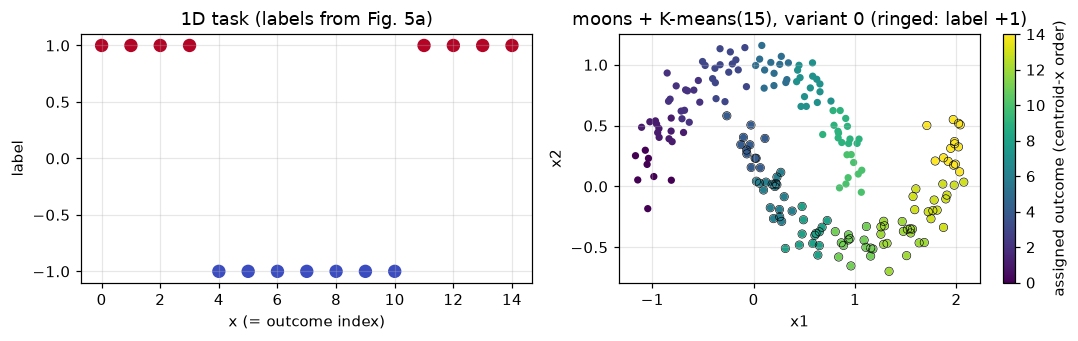

In [2]:
one_d = build_dataset({"name": "nonlinear_1d", "n_points": 15})
print("1D labels by x:", one_d.labels.tolist())

MOONS = {"name": "moons_kmeans", "n_samples": 200, "noise": 0.1, "n_clusters": 15,
         "data_seed": 0, "kmeans_seed": 0, "assignment": "x_order", "assignment_seed": 0}
moons = build_dataset(MOONS)
print("moons: points", len(moons.labels), "| clusters", len(np.unique(moons.outcome_index)),
      "| weighted cluster purity", round(moons.extras["weighted_purity"], 3))

seed = 7
train_a, test_a = partition_indices(15, 0.2, seed)
train_b, test_b = partition_indices(15, 0.2, seed)
assert np.array_equal(test_a, test_b), "partitions must be deterministic per seed"
print("1D split seed 7 -> test points", test_a.tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].scatter(one_d.features[:, 0], one_d.labels, c=one_d.labels, cmap="coolwarm", s=60)
axes[0].set(xlabel="x (= outcome index)", ylabel="label", title="1D task (labels from Fig. 5a)")
sc = axes[1].scatter(*moons.features.T, c=moons.outcome_index, cmap="viridis", s=14,
                     marker="o")
axes[1].scatter(*moons.features[moons.labels == 1].T, facecolors="none", edgecolors="k",
                s=30, lw=0.4)
fig.colorbar(sc, ax=axes[1], label="assigned outcome (centroid-x order)")
axes[1].set(xlabel="x1", ylabel="x2", title="moons + K-means(15), variant 0 (ringed: label +1)")
plt.tight_layout()
plt.show()

## 3. The ABS feature map in a few equations

$n$ single photons enter an $m$-mode interferometer. Of these, $r$ photons are
detected on $k$ adaptive modes, giving the pattern $p=(p_1,\dots,p_k)$. The
circuit for pattern $p$ is a unitary $U_p$, which in platforms B2/B3 is

$$U_p = A_p\,U_0 ,$$

where $U_0$ is a fixed random interferometer and $A_p$ is an adaptive block of
Mach-Zehnder interferometers (MZIs) whose phases depend on $p$. Post-selecting
$p$ leaves the residual photons in

$$|\psi_p\rangle \propto \big(\langle p|_{\text{detected}}\otimes \mathbb 1\big)\,
\Phi(U_p)\,|1,\dots,1\rangle ,\qquad
\Pr(p)=\big\|\cdots\big\|^2 .$$

Here $\Phi(U)$ is the Fock-space action of the interferometer, whose amplitudes
are matrix permanents. The kernel is

$$K(p,q)=|\langle\psi_p|\psi_q\rangle|^2 .$$

For the mixed states measured in the experiment, the kernel is instead the
Uhlmann fidelity $F(\rho_p,\rho_q)$. The residual dimension is
$d=\binom{m-k+n-r-1}{n-r}$.

**Conventions.** Each MZI is $B\,\mathrm{diag}(e^{i\theta},1)\,B$ with
$B=\tfrac{1}{\sqrt2}\begin{pmatrix}1&i\\ i&1\end{pmatrix}$. This is the only
convention we found that reproduces the paper's printed platform-A kernel
(Section 4).

**LIVE:** the platforms as implemented in `lib/circuits.py`, in the paper's
$[m,n,d,D]$ notation, where $D$ is the number of encodable patterns.

In [3]:
rows = []
for name in ("A", "B1", "B2", "B3"):
    p = get_platform(name)
    rows.append({"platform": name, "m (modes)": p.n_modes, "n (photons)": len(p.input_modes),
                 "d (residual dim.)": p.output_dimension, "D (patterns)": len(p.outcomes),
                 "adaptive detectors": len(p.detected_modes),
                 "random U_0 (unpublished)": p.needs_random_u0})
pd.DataFrame(rows).set_index("platform")

,m (modes),n (photons),d (residual dim.),D (patterns),adaptive detectors,random U_0 (unpublished)
platform,,,,,,
A,6,2,2,3,4,False
B1,8,3,2,15,6,False
B2,8,3,2,15,6,True
B3,8,3,3,15,5,True


## 4. Known-answer sanity checks

Before trusting the B2/B3 results, we check the simulator on three cases whose
answers are known.

1. **Hong-Ou-Mandel effect.** Two photons on a 50:50 splitter never leave in
   different ports.
2. **Platform A.** The paper prints the theoretical kernel 0.298 / 0.966 /
   0.331 (Fig. 3b). This fixes the MZI convention and the outcome order.
3. **Kernel validity.** Every kernel must have a unit diagonal, be symmetric and
   be positive semi-definite.

In [4]:
bs = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)
coincidence = transition_amplitude(bs, [1, 1], [1, 1])
print(f"HOM coincidence amplitude |<1,1|U|1,1>| = {abs(coincidence):.1e}  (expected 0)")

platform_a = get_platform("A")
states_a, prob_a = state_table(platform_a, None)
kernel_a = quantum_kernel(states_for_assignment(states_a, range(3)), "overlap")
ours = np.array([kernel_a[0, 1], kernel_a[0, 2], kernel_a[1, 2]])
printed = np.array([0.298, 0.966, 0.331])
display(pd.DataFrame({"paper (Fig. 3b)": printed, "ours": ours.round(4),
                      "|difference|": np.abs(ours - printed).round(4)},
                     index=["K(0,1)", "K(0,2)", "K(1,2)"]))
assert np.abs(ours - printed).max() < 1e-3

eigenvalues = np.linalg.eigvalsh(kernel_a)
print("unit diagonal:", np.allclose(np.diag(kernel_a), 1),
      "| symmetric:", np.allclose(kernel_a, kernel_a.T),
      "| min eigenvalue:", round(eigenvalues.min(), 6))

HOM coincidence amplitude |<1,1|U|1,1>| = 2.2e-17  (expected 0)


,paper (Fig. 3b),ours,|difference|
"K(0,1)",0.298,0.2984,0.0004
"K(0,2)",0.966,0.9660,0.0000
"K(1,2)",0.331,0.3316,0.0006


unit diagonal: True | symmetric: True | min eigenvalue: 0.033405


**Observation.** The HOM amplitude vanishes, and platform A matches the printed
kernel to within $6.3\times10^{-4}$.

**Inference.** The Fock simulation, the MZI convention and the outcome order are
correct for a fully published circuit.

**Remaining uncertainty.** Platform A has only 3 outcomes. Platform B1 is also
fully published, yet we could **not** match its Fig. 3e heatmap (Section 10).

**Claim impact.** C1 is reproduced for platform A.

## 5. Pipeline walkthrough: from circuit to kernel

Platforms B2 and B3 need the random interferometer $U_0$, which the paper does
not publish. The kernel's structure depends entirely on it.

**LIVE, step 1: a Haar-random $U_0$.** This is the naive substitute. We compare
its kernel with the "simulated" B2 panel digitised from Fig. 4a.

In [5]:
platform_b2, platform_b3 = get_platform("B2"), get_platform("B3")
target = {"B2": digitised("fig4a_B2_simulated"), "B3": digitised("fig4b_B3_simulated")}
experimental = {"B2": digitised("fig4a_B2_experimental"), "B3": digitised("fig4b_B3_experimental")}


def abs_kernel(platform, u0, assignment=None):
    states, probabilities = state_table(platform, u0)
    assignment = range(len(platform.outcomes)) if assignment is None else assignment
    return quantum_kernel(states_for_assignment(states, assignment), "overlap"), probabilities


haar_kernel, _ = abs_kernel(platform_b2, random_u0(8, 0))
print(f"Haar U_0 (seed 0): Pearson r with the digitised Fig. 4a simulated panel = "
      f"{pearson_upper(haar_kernel, target['B2']):.2f}")

Haar U_0 (seed 0): Pearson r with the digitised Fig. 4a simulated panel = 0.19


The Haar kernel has no visible relation to the paper's band-shaped kernel. Over
10 seeds, the stored runs give $r=-0.02$ to $0.59$.

**LIVE, step 2: fit $U_0$ to the paper's own simulated panel.**

- Parametrise $U_0=e^{iH}$ and minimise the kernel's mean squared error with
  Adam, through an autograd 3×3 permanent (`lib/u0_fit.py`).
- Use 8 random starts per fit, 1500 steps each, learning rate 0.05, and keep the
  best start.
- Run 5 independent fits per platform: fit $s$ uses starts $8s,\dots,8s+7$. This
  is the configuration of the stored runs.

The fit uses paper data, so agreement with the **fitted** panel is not
independent evidence. The real test is the **experimental** panel, which the fit
never sees.

In [6]:
FIT = {"n_candidates": 8, "n_steps": 1500, "learning_rate": 0.05, "fit_seeds": range(5)}
fitted = {"B2": [], "B3": []}
started = time.perf_counter()
for name, platform in (("B2", platform_b2), ("B3", platform_b3)):
    for fit_seed in FIT["fit_seeds"]:
        starts = [fit_seed * FIT["n_candidates"] + c for c in range(FIT["n_candidates"])]
        u0, _ = fit_u0_to_kernel(platform, target[name], starts, FIT["n_steps"],
                                 FIT["learning_rate"])
        kernel, probabilities = abs_kernel(platform, u0)
        fitted[name].append({"u0": u0, "kernel": kernel, "probabilities": probabilities})
print(f"10 fits in {time.perf_counter() - started:.0f} s")

rows = []
for name in ("B2", "B3"):
    for fit_seed, item in enumerate(fitted[name]):
        rows.append({"platform": name, "fit": fit_seed,
                     "r vs simulated panel (fitted)": pearson_upper(item["kernel"], target[name]),
                     "MAE vs simulated panel": np.abs(item["kernel"] - target[name]).mean(),
                     "r vs experimental panel (NOT fitted)": pearson_upper(item["kernel"], experimental[name]),
                     "total post-selection probability": np.diag(item["probabilities"]).sum()})
fit_table = pd.DataFrame(rows).round(3)
fit_table

10 fits in 59 s


,platform,fit,r vs simulated panel (fitted),MAE vs simulated panel,r vs experimental panel (NOT fitted),total post-selection probability
0,B2,0,1.000,0.002,0.991,0.275
1,B2,1,1.000,0.002,0.991,0.507
2,B2,2,1.000,0.002,0.991,0.642
3,B2,3,1.000,0.002,0.991,0.540
4,B2,4,1.000,0.002,0.991,0.592
5,B3,0,0.995,0.021,0.967,0.644
6,B3,1,0.995,0.020,0.965,0.616
7,B3,2,0.996,0.022,0.971,0.242
8,B3,3,0.995,0.020,0.967,0.462
9,B3,4,0.993,0.026,0.965,0.347


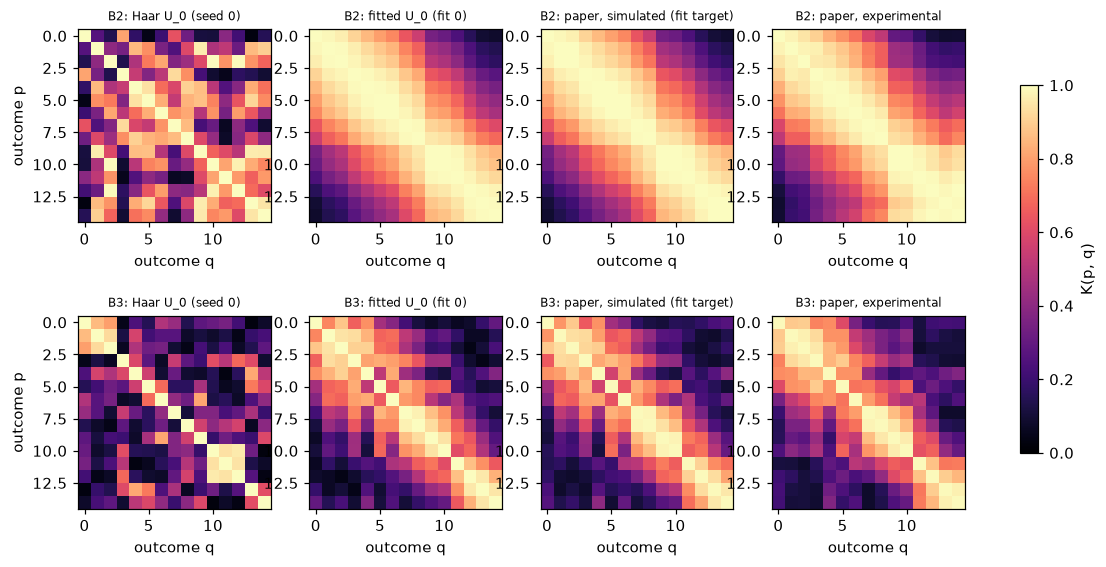

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for row, name in enumerate(("B2", "B3")):
    panels = [(haar_kernel if name == "B2" else abs_kernel(platform_b3, random_u0(8, 0))[0],
               f"{name}: Haar U_0 (seed 0)"),
              (fitted[name][0]["kernel"], f"{name}: fitted U_0 (fit 0)"),
              (target[name], f"{name}: paper, simulated (fit target)"),
              (experimental[name], f"{name}: paper, experimental")]
    for column, (axis, (matrix, title)) in enumerate(zip(axes[row], panels)):
        image = axis.imshow(matrix, vmin=0, vmax=1, cmap="magma")
        axis.set_title(title, fontsize=8)
        axis.set_xlabel("outcome q")
        if column == 0:
            axis.set_ylabel("outcome p")
        axis.grid(False)
fig.colorbar(image, ax=axes, shrink=0.7, label="K(p, q)")
plt.show()

**Observation.**

- A fitted $U_0$ reproduces the simulated panels: $r\approx1.00$ for B2 and
  0.99 for B3.
- It also predicts the **unfitted** experimental panels at $r=0.96$-$0.99$.
- The 5 fits are different matrices, with different post-selection
  probabilities.

**Inference.** The published adaptive blocks and our reading of the angle rule
are consistent with the paper. The unpublished $U_0$ was the missing piece.

**Remaining uncertainty.** The fitted $U_0$ is one of many matrices that
reproduce the panel, so it is not the authors' matrix. Downstream accuracies
(next sections) agree across fits.

**Claim impact.** C1 for B2/B3 is reproduced, with a substitute $U_0$.

## 6. Small live experiment: 1D classification

**LIVE.** We classify the 15-point 1D set with the paper's protocol, using:

- the kernels digitised from the paper (experimental and simulated panels);
- the ideal kernels of our 5 fitted $U_0$ per platform.

Each point $x$ uses kernel row $x$, so the point kernel is the 15×15 outcome
kernel itself.

In [8]:
labels_1d = one_d.labels
rows, per_partition = [], {}
for label, matrix in [("qubit, digitised experimental (Fig. 4a)", experimental["B2"]),
                      ("qubit, digitised simulated (Fig. 4a)", target["B2"]),
                      ("qutrit, digitised experimental (Fig. 4b)", experimental["B3"]),
                      ("qutrit, digitised simulated (Fig. 4b)", target["B3"])]:
    scores = accuracies(matrix, labels_1d, 15)
    per_partition[label] = scores
    rows.append({"kernel": label, "mean test accuracy": scores.mean(),
                 "SE over partitions": scores.std(ddof=1) / 10, "fits": 1})
for name, word in (("B2", "qubit"), ("B3", "qutrit")):
    fit_means = [accuracies(item["kernel"], labels_1d, 15).mean() for item in fitted[name]]
    rows.append({"kernel": f"{word}, ideal kernel of fitted U_0", "mean test accuracy": np.mean(fit_means),
                 "SE over partitions": np.std(fit_means, ddof=1), "fits": 5,
                 "individual fits": np.round(fit_means, 3).tolist()})
live_1d = pd.DataFrame(rows)
live_1d["paper"] = [0.90, 0.90, 0.80, 0.80, 0.90, 0.80]
live_1d.round(3)

,kernel,mean test accuracy,SE over partitions,fits,individual fits,paper
0,"qubit, digitised experimental (Fig. 4a)",0.803,0.018,1,NaN,0.9
1,"qubit, digitised simulated (Fig. 4a)",0.763,0.021,1,NaN,0.9
2,"qutrit, digitised experimental (Fig. 4b)",0.773,0.025,1,NaN,0.8
3,"qutrit, digitised simulated (Fig. 4b)",0.783,0.023,1,NaN,0.8
4,"qubit, ideal kernel of fitted U_0",0.762,0.018,5,"[0.793, 0.75, 0.753, 0.763, 0.75]",0.9
5,"qutrit, ideal kernel of fitted U_0",0.780,0.026,5,"[0.777, 0.777, 0.82, 0.747, 0.78]",0.8


For the fitted-$U_0$ rows, the "SE" column holds the std over the 5 fits; the
individual values are listed.

**Live fits vs stored fits.** The stored runs fit the unrounded digitised panel,
while the live fits use the committed CSVs, which are rounded to $10^{-4}$. That
small change makes some fits settle on a different start, so the live $U_0$
matrices differ from the stored ones. The table above shows this, for example
in the post-selection probability of fit 0. The fitted panels agree equally well
either way. The stored 1D means over the 5 fits are 0.755 (qubit) and 0.761
(qutrit); the live values above fall within the spread of the individual fits.
This is the non-uniqueness of $U_0$ in action.

**Observation.**

- **Qutrit:** about 0.77-0.78 against the paper's 0.80, within about 1 SE.
- **Qubit:** about 0.76-0.80 against the paper's 0.90.

**Inference.** The qutrit result reproduces. Section 10 shows that the qubit gap
is within what a digitised figure can resolve.

**Remaining uncertainty.** Each test set has 3 points, so per-split accuracies
are coarse. The paper's split seeds are unknown.

**Claim impact.** C2 (1D) is reproduced for the qutrit; the qubit result is
unresolved.

## 7. Headline reproduction result

**STORED.** `results/fair_comparison.json` summarises the full runs:

- 1D: runs `run_20261104-231701` (digitised kernels) and `run_20261105-085018`
  (fitted $U_0$);
- moons, centroid-x rule: `run_20261105-085258`;
- moons, 20 random assignments: `run_20261104-232529`.

All runs use 100 partitions, C = 50, and seed 42, at code commit `e7beb6a` plus
the uncommitted paper folder. The stored runs used digitised kernels at full
precision; the CSVs used live above are rounded to $10^{-4}$, which accounts for
any third-decimal difference.

In [9]:
comparison = json.loads((RESULTS / "fair_comparison.json").read_text())
conditions = {c["name"]: c for c in comparison["conditions"]}


def stored(condition, model, arm="paper"):
    return conditions[condition]["arms"][arm]["models"][model]


headline = []
for condition, qubit, qutrit, paper in [
        ("1d", "B2_qubit_experimental_fig4a", "B3_qutrit_experimental_fig4b", (0.90, 0.80)),
        ("1d", "B2_qubit_fitted_u0", "B3_qutrit_fitted_u0", (0.90, 0.80)),
        ("moons_xorder_noise0.1", "B2_qubit_experimental_fig4a", "B3_qutrit_experimental_fig4b", (0.65, 0.90)),
        ("moons_random_assignments", "B2_qubit_experimental_fig4a", "B3_qutrit_experimental_fig4b", (0.65, 0.90)),
        ("moons_arc_order", "B2_qubit_experimental_fig4a", "B3_qutrit_experimental_fig4b", (0.65, 0.90))]:
    q, t = stored(condition, qubit), stored(condition, qutrit)
    headline.append({"condition": condition, "kernels": qubit.split("_", 2)[2],
                     "qubit": f"{q['mean_test_accuracy']:.3f} ± {q['variability']:.3f}",
                     "qutrit": f"{t['mean_test_accuracy']:.3f} ± {t['variability']:.3f}",
                     "paper qubit / qutrit": f"{paper[0]:.2f} / {paper[1]:.2f}",
                     "variants": q["n_variants"], "± is": q["variability_kind"]})
pd.DataFrame(headline)

,condition,kernels,qubit,qutrit,paper qubit / qutrit,variants,± is
0,1d,experimental_fig4a,0.803 ± 0.018,0.773 ± 0.025,0.90 / 0.80,1,SE over partitions
1,1d,fitted_u0,0.755 ± 0.022,0.761 ± 0.021,0.90 / 0.80,1,SE over partitions
2,moons_xorder_noise0.1,experimental_fig4a,0.614 ± 0.077,0.863 ± 0.061,0.65 / 0.90,9,std over variants
3,moons_random_assignments,experimental_fig4a,0.560 ± 0.113,0.791 ± 0.078,0.65 / 0.90,20,std over variants
4,moons_arc_order,experimental_fig4a,0.989 ± 0.019,0.991 ± 0.018,0.65 / 0.90,9,std over variants


**Observation.**

- **1D:** the qutrit result matches the paper; the qubit result is 0.10 low.
- **Moons:** the levels depend on the cluster-to-outcome rule.
  - The centroid-x rule gives 0.61 / 0.86, close to the paper's 0.65 / 0.90.
  - Random assignments give 0.56 / 0.79.
  - Moon-following "arc order" saturates near 0.99 for both kernels.

**Inference.** The paper's moons numbers are reachable with its own digitised
kernels. Which assignment the authors used is unknown.

**Remaining uncertainty.** We noticed the centroid-x rule after seeing the
paper's numbers. Section 9 treats it as one candidate among 21, not as the
answer.

**Claim impact.** C2 is partially reproduced: 1D qutrit yes, 1D qubit
unresolved, and the moons levels depend on the assignment.

## 8. Fair baseline comparison

The paper reports no classical baseline. We compare the ABS kernels with
classical models in three roles.

- **Information-matched kernel:** a Gaussian kernel on the **outcome index**,
  $K(i,j)=e^{-\gamma(i-j)^2}$, with $\gamma$ set by the median heuristic (not
  tuned). It sees exactly what the ABS kernel sees, namely which of the 15
  outcomes a point maps to.
- **Dimension-matched kernels:** random rank-$d$ kernels
  $|\langle u_i|u_j\rangle|^2$, with $u_i$ random unit vectors in
  $\mathbb C^d$, $d=2$ for the qubit and $d=3$ for the qutrit, 10 random seeds.
  They have the ABS feature-space dimension but no circuit structure.
- **Unmatched reference:** an RBF SVM on the raw coordinates. It sees more
  information (continuous $x$), so it is only an upper reference, not a fair
  comparator.

How the comparison is matched, dimension by dimension:

| Dimension | Status |
|---|---|
| Information and inputs | Matched for the outcome-index and rank-$d$ kernels (the same 15-outcome representation and the same assignment). Not matched for raw-feature models. |
| Parameter count | No model has trained parameters beyond the SVM dual. $U_0$ (64 real parameters) is fixed, fitted to the paper's kernel, not to labels. |
| Training data | Identical points, labels and 100 splits. |
| Optimisation steps | One convex SVM fit per split for every model. |
| Tuning budget | Paper arm: none (C = 50, fixed $\gamma$). Tuned arm (stored): the same 3-fold CV grid on training data for every model. |
| Compute and wall time | Not matched. The ABS kernel is a simulation here and needs post-selection (probabilities down to $3\times10^{-4}$) and tomography on hardware; the classical kernels are closed form. |
| Evaluation protocol | Identical metric, splits and C. |

**LIVE.** We re-run the moons comparison on all 9 dataset variants under the
centroid-x rule (noise 0.1), with the paper's digitised experimental kernels.

In [10]:
index_features = np.arange(15, dtype=float)[:, None]
outcome_gaussian = gaussian_kernel(index_features, median_heuristic_gamma(index_features))
outcome_kernels = {
    "ABS qubit (digitised exp.)": (experimental["B2"], "ABS"),
    "ABS qutrit (digitised exp.)": (experimental["B3"], "ABS"),
    "Gaussian on outcome index": (outcome_gaussian, "matched"),
    "random rank-2 (10 seeds)": ([random_rank_d_kernel(15, 2, s) for s in range(10)], "dimension"),
    "random rank-3 (10 seeds)": ([random_rank_d_kernel(15, 3, s) for s in range(10)], "dimension"),
}
variant_scores = {name: [] for name in outcome_kernels}
started = time.perf_counter()
for data_seed in range(3):
    for kmeans_seed in range(3):
        variant = build_dataset({**MOONS, "data_seed": data_seed, "kmeans_seed": kmeans_seed})
        index = variant.outcome_index
        for name, (matrices, _) in outcome_kernels.items():
            matrices = matrices if isinstance(matrices, list) else [matrices]
            per_kernel = [accuracies(m[np.ix_(index, index)], variant.labels, 200) for m in matrices]
            variant_scores[name].append(np.mean(per_kernel, axis=0))
print(f"9 variants x 5 kernel families in {time.perf_counter() - started:.0f} s")

summary = pd.DataFrame({name: [s.mean() for s in scores] for name, scores in variant_scores.items()})
summary.index.name = "variant (data seed, K-means seed)"
summary.index = [f"({d},{k})" for d in range(3) for k in range(3)]
display(summary.round(3))
display(summary.agg(["mean", "std"]).round(3))

9 variants x 5 kernel families in 23 s


,ABS qubit (digitised exp.),ABS qutrit (digitised exp.),Gaussian on outcome index,random rank-2 (10 seeds),random rank-3 (10 seeds)
"(0,0)",0.526,0.934,0.798,0.675,0.988
"(0,1)",0.523,0.905,0.762,0.656,0.986
"(0,2)",0.530,0.910,0.761,0.680,0.988
"(1,0)",0.642,0.891,0.883,0.705,0.954
"(1,1)",0.720,0.832,0.810,0.650,0.972
"(1,2)",0.592,0.870,0.888,0.653,0.966
"(2,0)",0.690,0.764,0.778,0.662,0.951
"(2,1)",0.616,0.886,0.746,0.714,0.937
"(2,2)",0.689,0.773,0.767,0.659,0.940


,ABS qubit (digitised exp.),ABS qutrit (digitised exp.),Gaussian on outcome index,random rank-2 (10 seeds),random rank-3 (10 seeds)
mean,0.614,0.863,0.799,0.673,0.965
std,0.076,0.060,0.053,0.023,0.020


In [11]:
def paired(first, second):
    # Paired difference over the 9 variants with a 95 % t-interval (frozen Phase 5 rule).
    from scipy import stats
    diff = np.array([a.mean() - b.mean() for a, b in zip(variant_scores[first], variant_scores[second])])
    half = stats.t.ppf(0.975, diff.size - 1) * diff.std(ddof=1) / np.sqrt(diff.size)
    verdict = ("no clear separation" if abs(diff.mean()) <= 0.02 or abs(diff.mean()) <= half
               else ("first higher" if diff.mean() > 0 else "second higher"))
    return {"first": first, "second": second, "difference": round(diff.mean(), 3),
            "95% CI": f"[{diff.mean() - half:+.3f}, {diff.mean() + half:+.3f}]", "verdict": verdict}


pd.DataFrame([paired("ABS qutrit (digitised exp.)", "Gaussian on outcome index"),
              paired("ABS qubit (digitised exp.)", "Gaussian on outcome index"),
              paired("ABS qutrit (digitised exp.)", "random rank-3 (10 seeds)"),
              paired("ABS qubit (digitised exp.)", "random rank-2 (10 seeds)")])

,first,second,difference,95% CI,verdict
0,ABS qutrit (digitised exp.),Gaussian on outcome index,0.064,"[+0.006, +0.121]",first higher
1,ABS qubit (digitised exp.),Gaussian on outcome index,-0.185,"[-0.252, -0.118]",second higher
2,ABS qutrit (digitised exp.),random rank-3 (10 seeds),-0.102,"[-0.141, -0.063]",second higher
3,ABS qubit (digitised exp.),random rank-2 (10 seeds),-0.059,"[-0.123, +0.005]",no clear separation


**STORED.** The same comparison for every condition:

- 1D, both moons noise levels, random assignments and arc order;
- MerLin kernels included;
- run `run_20261105-154638` and the other runs listed in
  `results/fair_comparison_manifest.json`.

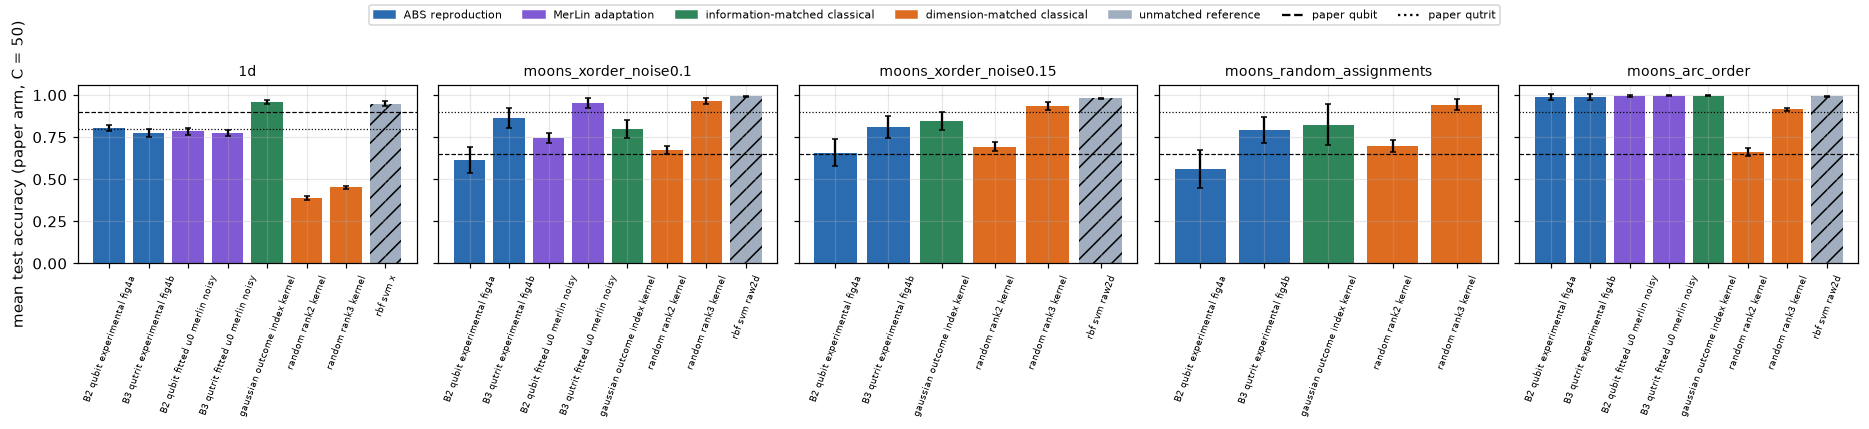

In [12]:
show = {"B2_qubit_experimental_fig4a": "ABS", "B3_qutrit_experimental_fig4b": "ABS",
        "B2_qubit_fitted_u0_merlin_noisy": "MerLin", "B3_qutrit_fitted_u0_merlin_noisy": "MerLin",
        "gaussian_outcome_index_kernel": "matched", "random_rank2_kernel": "dimension",
        "random_rank3_kernel": "dimension", "rbf_svm_x": "unmatched", "rbf_svm_raw2d": "unmatched"}
names = ["1d", "moons_xorder_noise0.1", "moons_xorder_noise0.15", "moons_random_assignments",
         "moons_arc_order"]
fig, axes = plt.subplots(1, len(names), figsize=(17, 3.9), sharey=True)
for axis, name in zip(axes, names):
    models = conditions[name]["arms"]["paper"]["models"]
    labels = [label for label in show if label in models]
    for position, label in enumerate(labels):
        model = models[label]
        axis.bar(position, model["mean_test_accuracy"], yerr=model["variability"],
                 color=COLORS[show[label]], capsize=2,
                 hatch="//" if show[label] == "unmatched" else None)
    paper = conditions[name]["paper"]
    axis.axhline(paper["qubit_B2"], color="k", ls="--", lw=0.8)
    axis.axhline(paper["qutrit_B3"], color="k", ls=":", lw=0.8)
    axis.set_xticks(range(len(labels)), [label.replace("_", " ") for label in labels], rotation=70, fontsize=6)
    axis.set_title(name, fontsize=9)
axes[0].set_ylabel("mean test accuracy (paper arm, C = 50)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for k, c in COLORS.items() if k != "paper"]
handles += [plt.Line2D([], [], color="k", ls="--"), plt.Line2D([], [], color="k", ls=":")]
fig.legend(handles, ["ABS reproduction", "MerLin adaptation", "information-matched classical",
                     "dimension-matched classical", "unmatched reference",
                     "paper qubit", "paper qutrit"], loc="upper center", ncol=7, fontsize=7)
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

**Observation.**

- **1D:** the information-matched Gaussian kernel (0.96) beats every ABS kernel
  (0.75-0.80), and the 95 % interval excludes 0.
- **Moons:**
  - The ABS qutrit kernel beats it only under the centroid-x rule at noise 0.1,
    by +0.06 for the digitised experimental kernel; the live re-run above shows
    the same.
  - Elsewhere the qutrit kernel ties or loses, and the qubit kernel always loses.
  - The random rank-3 kernel beats the ABS qutrit kernel under centroid-x and
    random assignments.

**Inference.** On these tasks, ABS kernels are good kernels but not better ones.
A classical kernel with the same input does as well or better.

**Remaining uncertainty.** These are our regenerated datasets and splits, so the
comparison holds for them, not necessarily for the authors' data. The 1D set is
probably the paper's own, since it was read from Fig. 5a.

**Claim impact.** C2 is weakened as evidence of usefulness, but not contradicted:
the paper only claims successful classification. No advantage is supported.

## 9. Controls and ablations

Three alternative explanations need to be ruled in or out.

1. **Is the qutrit gain specific to ABS?** Control: random rank-3 vs rank-2
   classical kernels.
2. **Is the moons result an artefact of one assignment rule?** Control: a
   declared sweep over 7 parameter-free rules × 3 noise levels.
   - Its plan, metric and "no selection" rule were recorded before launch.
   - It is a `COMPLETE SWEEP`: 21/21 runs completed.
3. **Are the alternative kernels better than chance kernels (C4)?** Control:
   permuted Gaussian kernels and random rank-$d$ kernels.

In [13]:
dimension_rows = []
for name in names:
    for pair in conditions[name]["arms"]["paper"]["dimension_effect"]:
        if pair["first"] in ("B3_qutrit_experimental_fig4b", "B3_qutrit_fitted_u0_merlin_noisy",
                             "random_rank3_kernel"):
            dimension_rows.append({"condition": name, "d = 3 minus d = 2": f"{pair['first']} - {pair['second']}",
                                   "difference": round(pair["difference"], 3),
                                   "95% CI": f"[{pair['ci95'][0]:+.3f}, {pair['ci95'][1]:+.3f}]",
                                   "verdict": pair["verdict"]})
pd.DataFrame(dimension_rows)

,condition,d = 3 minus d = 2,difference,95% CI,verdict
0,1d,B3_qutrit_experimental_fig4b - B2_qubit_experi...,-0.030,"[-0.082, +0.022]",no clear separation
1,1d,B3_qutrit_fitted_u0_merlin_noisy - B2_qubit_fi...,-0.009,"[-0.028, +0.010]",no clear separation
2,1d,random_rank3_kernel - random_rank2_kernel,0.063,"[+0.037, +0.089]",first higher
3,moons_xorder_noise0.1,B3_qutrit_experimental_fig4b - B2_qubit_experi...,0.249,"[+0.148, +0.351]",first higher
4,moons_xorder_noise0.1,B3_qutrit_fitted_u0_merlin_noisy - B2_qubit_fi...,0.206,"[+0.186, +0.227]",first higher
5,moons_xorder_noise0.1,random_rank3_kernel - random_rank2_kernel,0.292,"[+0.264, +0.320]",first higher
6,moons_xorder_noise0.15,B3_qutrit_experimental_fig4b - B2_qubit_experi...,0.155,"[+0.064, +0.246]",first higher
7,moons_xorder_noise0.15,random_rank3_kernel - random_rank2_kernel,0.240,"[+0.206, +0.275]",first higher
8,moons_random_assignments,B3_qutrit_experimental_fig4b - B2_qubit_experi...,0.231,"[+0.173, +0.289]",first higher
9,moons_random_assignments,random_rank3_kernel - random_rank2_kernel,0.245,"[+0.222, +0.268]",first higher


**Observation (control 1).**

- **Moons:** random rank-3 minus rank-2 kernels gain +0.24 to +0.29, at least
  as much as the ABS qutrit-minus-qubit gain (+0.16 to +0.25).
- **1D:** ABS shows no dimension effect, while the random kernels gain +0.06.

**Inference.** Going from 4 to 9 real feature dimensions helps on moons no matter
where the kernel comes from. The qutrit gain is a generic dimension effect.

**Claim impact.** C3 is reproduced as an observation on moons, but it is weakened
as a property of ABS.

**STORED (control 2).** The full sweep table is in
`results/moons_assignment_sweep.csv`. It covers runs `run_20261105-090245` to
`run_20261105-090435`, plus the coordinator's `sweep_status.json`.

runs: 21 / 21 | qutrit above qubit in 21 / 21 candidates


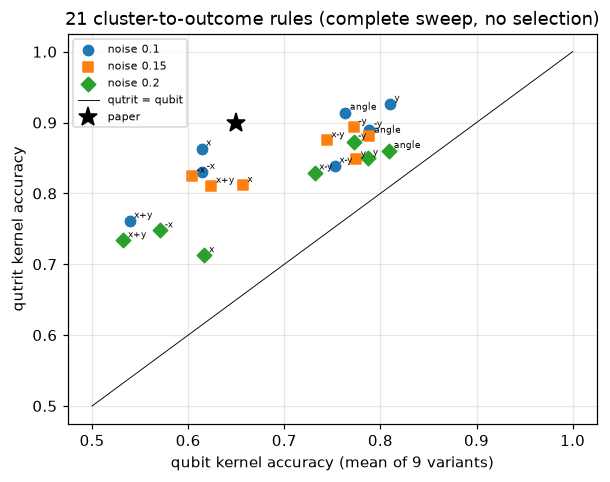

In [14]:
sweep = pd.read_csv(RESULTS / "moons_assignment_sweep.csv")
sweep = sweep[sweep["model"].str.contains("experimental")]
pivot = sweep.pivot_table(index=["rank_rule", "noise"], columns="model", values="mean_test_accuracy")
pivot.columns = ["qubit (Fig. 4a exp.)", "qutrit (Fig. 4b exp.)"]
pivot["qutrit - qubit"] = pivot.iloc[:, 1] - pivot.iloc[:, 0]
assert len(pivot) == 21, "the sweep must have all 21 candidates"
print(f"runs: {sweep['run_id'].nunique()} / 21 | qutrit above qubit in "
      f"{int((pivot['qutrit - qubit'] > 0).sum())} / 21 candidates")

fig, axis = plt.subplots(figsize=(6.2, 4.6))
for noise, marker in zip((0.1, 0.15, 0.2), "osD"):
    block = pivot.xs(noise, level="noise")
    axis.scatter(block.iloc[:, 0], block.iloc[:, 1], marker=marker, s=45, label=f"noise {noise}")
    for rule, (x, y) in block.iloc[:, :2].iterrows():
        axis.annotate(rule, (x, y), fontsize=6, xytext=(3, 2), textcoords="offset points")
axis.plot([0.5, 1], [0.5, 1], "k-", lw=0.6, label="qutrit = qubit")
axis.plot(0.65, 0.90, "k*", ms=13, label="paper")
axis.set(xlabel="qubit kernel accuracy (mean of 9 variants)",
         ylabel="qutrit kernel accuracy", title="21 cluster-to-outcome rules (complete sweep, no selection)")
axis.legend(fontsize=7)
plt.show()

**Observation (control 2).** Every one of the 21 rules puts the qutrit above the
qubit. Only the $\pm x$ centroid rules come close to the paper's levels (the
star).

**Inference.** The qutrit > qubit ordering does not depend on the assignment
rule. The accuracy levels do, and they point at a centroid-x-like assignment in
the paper. That reading is plausible but unconfirmed.

**STORED (control 3).** Alternative kernels (C4), from `statistics.json` (runs
`run_20261105-085130` and `run_20261104-231744`). The live cell then recomputes
one fit's 50 alternatives.

,role,n_kernels,mean_test_accuracy,fraction_in_paper_range,min,max
B2_qubit_alternative,ABS reproduction,250,0.820,0.824,0.553333,0.996667
B3_qutrit_alternative,ABS reproduction,250,0.815,0.812,0.553333,1.0
B2_qubit_alternative_merlin,"ABS, MerLin adaptation",250,0.820,0.824,0.553333,0.996667
B2_qubit_alternative_merlin_noisy,"ABS, MerLin adaptation",250,0.837,0.884,0.593333,1.0
B3_qutrit_alternative_merlin,"ABS, MerLin adaptation",250,0.815,0.812,0.553333,1.0
B3_qutrit_alternative_merlin_noisy,"ABS, MerLin adaptation",250,0.855,0.936,0.62,1.0
gaussian_index_permuted,"classical, information-matched",50,0.480,0.08,0.133333,0.94
random_rank2_kernel,"classical, dimension-matched (d = 2)",50,0.444,0.04,0.133333,0.916667
random_rank3_kernel,"classical, dimension-matched (d = 3)",50,0.467,0.02,0.243333,0.743333


2 x 5 x 50 alternative kernels in 28 s


,kernels,mean,"in [0.73, 1.0]"
B2,250.0,0.853,0.960
B3,250.0,0.800,0.748


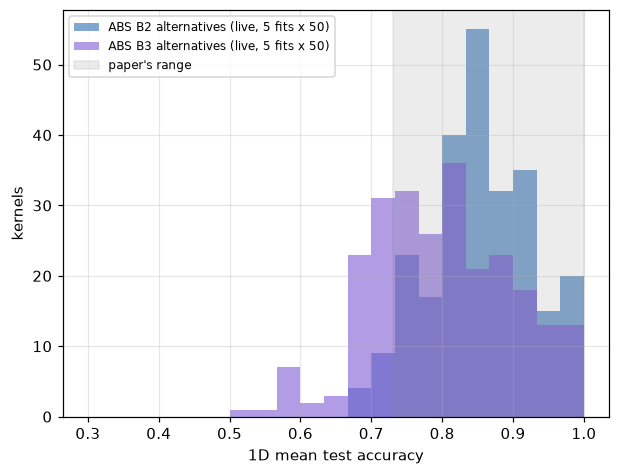

In [15]:
fair_alt = comparison["alternatives"]["models"]
display(pd.DataFrame(fair_alt).T[["role", "n_kernels", "mean_test_accuracy", "fraction_in_paper_range",
                                  "min", "max"]].astype({"mean_test_accuracy": float}).round(3))

# LIVE: the stored protocol on our live fits. 50 seeded random assignments
# (numpy default_rng(0), the same draws as the stored runs) for each of the 5 fits.
rng = np.random.default_rng(0)
assignments = [rng.permutation(15) for _ in range(50)]
live_alternatives = {}
started = time.perf_counter()
for name, platform in (("B2", platform_b2), ("B3", platform_b3)):
    scores = []
    for item in fitted[name]:
        states, _ = state_table(platform, item["u0"])
        for assignment in assignments:
            kernel = quantum_kernel(states_for_assignment(states, assignment), "overlap")
            scores.append(accuracies(kernel, labels_1d, 15).mean())
    live_alternatives[name] = np.array(scores)
print(f"2 x 5 x 50 alternative kernels in {time.perf_counter() - started:.0f} s")
display(pd.DataFrame({name: {"kernels": len(s), "mean": s.mean(),
                             "in [0.73, 1.0]": np.mean((s >= 0.73) & (s <= 1.0))}
                      for name, s in live_alternatives.items()}).T.round(3))

bins = np.linspace(0.3, 1, 22)
for name, color in (("B2", COLORS["ABS"]), ("B3", COLORS["MerLin"])):
    plt.hist(live_alternatives[name], bins=bins, alpha=0.6, color=color,
             label=f"ABS {name} alternatives (live, 5 fits x 50)")
plt.axvspan(0.73, 1.0, color="grey", alpha=0.15, label="paper's range")
plt.xlabel("1D mean test accuracy")
plt.ylabel("kernels")
plt.legend(fontsize=8)
plt.show()

The live run uses the same assignment draws as the stored runs, but its $U_0$
fits are not the stored ones (see the note in Section 6), so its numbers differ
slightly. The stored table is the reference.

**Observation (control 3).**

- **Stored runs:** 81-82 % of the re-assigned ABS kernels fall in the paper's
  0.73-1.0, against 2-8 % for permuted or random classical kernels.
- **Live fits:** 96 % (qubit) and 75 % (qutrit).

**Inference.** Re-assigning outcomes to circuits keeps a band structure that
suits this task. The exact fraction depends on which of the many valid fitted
$U_0$ is used, roughly ±0.15 here. Every fit stays far above the classical
controls. Permuting a classical kernel's outcome order destroys locality,
so that control is harsher than an ABS re-assignment. The result shows
robustness, not advantage.

**Claim impact.** C4 is reproduced, with a substitute $U_0$.

## 10. Robustness and uncertainty

**Digitisation.** The 1D qubit gap (0.80 vs 0.90) could come from the
digitisation itself. Two points sit at the class boundary, $x=9$ and $10$, and
the qubit kernel nearly ties there.

**STORED:** `results/digitization_sensitivity_1d.json`. It perturbs the
digitised kernel by the colour-quantisation error ($\sigma=0.01$) and varies the
split protocol and C.

In [16]:
sensitivity = json.loads((RESULTS / "digitization_sensitivity_1d.json").read_text())["kernels"]
rows = []
for key, entry in sensitivity.items():
    perturbed = entry["perturbation_sklearn_seeds_C50"]["0.01"]
    rows.append({"kernel": key, "paper": entry["paper_accuracy"],
                 "own splits, C=50": entry["protocol_grid"]["runner_seeds/C=50"],
                 "sklearn splits, C=50": entry["protocol_grid"]["sklearn_seeds/C=50"],
                 "C=1000": entry["protocol_grid"]["runner_seeds/C=1000"],
                 "sigma=0.01: mean": perturbed["mean"], "5th pct": perturbed["p05"], "95th pct": perturbed["p95"]})
pd.DataFrame(rows).set_index("kernel").round(3)

,paper,"own splits, C=50","sklearn splits, C=50",C=1000,sigma=0.01: mean,5th pct,95th pct
kernel,,,,,,,
fig4a_B2_experimental,0.9,0.803,0.840,0.880,0.860,0.787,0.933
fig4a_B2_simulated,0.9,0.763,0.763,0.750,0.803,0.753,0.877
fig4b_B3_experimental,0.8,0.773,0.773,0.773,0.781,0.767,0.790
fig4b_B3_simulated,0.8,0.783,0.763,0.783,0.770,0.733,0.787


**Observation.** For the experimental qubit kernel, perturbing entries by 0.01
gives 0.86 ± 0.05. The central 90 % spans 0.79-0.93, which includes the paper's
0.90. The qutrit kernel is stable under the same tests.

**Inference.** The 1D qubit gap is within what a digitised figure can resolve.
It can be neither confirmed nor refuted from the figure.

**Individual results.** The moons dataset variants from the live run in
Section 8, one point per variant:

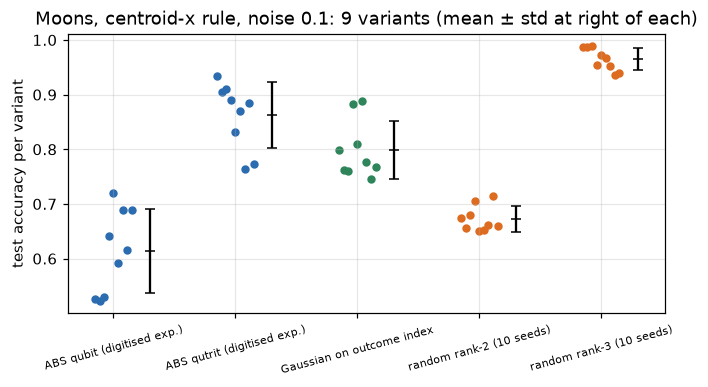

In [17]:
fig, axis = plt.subplots(figsize=(7, 3.3))
for offset, (name, (_, role)) in enumerate(outcome_kernels.items()):
    values = [s.mean() for s in variant_scores[name]]
    axis.scatter(np.full(9, offset) + np.linspace(-0.15, 0.15, 9), values, color=COLORS[role], s=20)
    axis.errorbar(offset + 0.3, np.mean(values), yerr=np.std(values, ddof=1), fmt="k_", capsize=3)
axis.set_xticks(range(len(outcome_kernels)), list(outcome_kernels), rotation=15, fontsize=7)
axis.set_ylabel("test accuracy per variant")
axis.set_title("Moons, centroid-x rule, noise 0.1: 9 variants (mean ± std at right of each)")
plt.show()

**Platform B1: a negative result.** Fig. 3e's B1 kernel is **not** reproduced by
the fully published circuit. The stored diagnoses ruled out:

- every outcome order (`results/b1_diagnosis.json`; best $r=0.92$ against 0.75
  for a random control);
- 176 circuit conventions, of which only the 4 that reproduce platform A were
  kept (`results/b1_models.json`);
- partial distinguishability and multiphoton noise (Section 11).

The likely cause is the chip's calibrated phases, which are unpublished. **C1 is
not reproduced for B1.**

## 11. Photonic assessment (MerLin)

Status: `MERLIN_IMPLEMENTATION`. This is an **adaptation of the simulator**, not
part of the reproduction above.

- **The paper is already photonic.** MerLin can express the same circuits
  directly (`lib/abs_merlin.py`). Each programmed mesh becomes a `pcvl.Circuit`
  inside a `merlin.QuantumLayer`.
- **Exact path.** `MeasurementStrategy.partial(adaptive detectors,
  ComputationSpace.FOCK)` returns one branch per detection outcome. The branch's
  amplitudes are $|\psi_p\rangle$. FOCK space is required because B3
  post-selects bunched outcomes.
- **Noisy path** (the paper's imperfect-source model, SI Note 6).
  `pcvl.NoiseModel(indistinguishability=0.83, g2=0.02)` with `probs(FOCK)`,
  followed by simulated tomography (linear inversion, PSD projection) and an
  Uhlmann-fidelity kernel. Losses are not modelled.
- **Mappings considered and rejected:** a generic trainable MerLin classifier and
  MerLin's built-in kernel classes (both drop adaptive post-selection), and a
  single non-adaptive circuit (that is claim C6).

**LIVE.** The exact MerLin backend against our numpy simulator, for platform A
and for B2/B3 with the fitted $U_0$.

In [18]:
from lib.abs_merlin import merlin_state_table, noisy_density_table  # noqa: E402

rows = []
for name, platform, u0 in [("A", platform_a, None), ("B2", platform_b2, fitted["B2"][0]["u0"]),
                           ("B3", platform_b3, fitted["B3"][0]["u0"])]:
    started = time.perf_counter()
    merlin_states, _ = merlin_state_table(platform, u0)
    elapsed = time.perf_counter() - started
    identity = range(len(platform.outcomes))
    k_merlin = quantum_kernel(states_for_assignment(merlin_states, identity), "overlap")
    k_numpy = quantum_kernel(states_for_assignment(state_table(platform, u0)[0], identity), "overlap")
    rows.append({"platform": name, "max |K_MerLin - K_numpy|": f"{np.abs(k_merlin - k_numpy).max():.1e}",
                 "MerLin wall-clock (s)": round(elapsed, 2)})
pd.DataFrame(rows)

,platform,max |K_MerLin - K_numpy|,MerLin wall-clock (s)
0,A,2.6e-15,0.02
1,B2,1.2e-15,0.06
2,B3,1.1e-15,0.05


In [19]:
NOISE = {"indistinguishability": 0.83, "g2": 0.02, "detection": "threshold"}
started = time.perf_counter()
density_b2, _ = noisy_density_table(platform_b2, fitted["B2"][0]["u0"], NOISE)
noisy_kernel = quantum_kernel(np.array([density_b2[k, k] for k in range(15)]), "fidelity")
elapsed = time.perf_counter() - started
ideal_kernel = fitted["B2"][0]["kernel"]
purities = [np.real(np.trace(density_b2[k, k] @ density_b2[k, k])) for k in range(15)]
print(f"noisy B2 kernel in {elapsed:.0f} s | state purity {min(purities):.3f}-{max(purities):.3f}")
pd.DataFrame({"kernel": ["ideal (fit 0)", "noisy source (fit 0)"],
              "r vs experimental panel": [pearson_upper(ideal_kernel, experimental["B2"]),
                                          pearson_upper(noisy_kernel, experimental["B2"])],
              "MAE vs experimental panel": [np.abs(ideal_kernel - experimental["B2"]).mean(),
                                            np.abs(noisy_kernel - experimental["B2"]).mean()],
              "1D accuracy": [accuracies(ideal_kernel, labels_1d, 15).mean(),
                              accuracies(noisy_kernel, labels_1d, 15).mean()]}).round(3)

noisy B2 kernel in 5 s | state purity 0.998-1.000


,kernel,r vs experimental panel,MAE vs experimental panel,1D accuracy
0,ideal (fit 0),0.991,0.026,0.793
1,noisy source (fit 0),0.989,0.029,0.787


**STORED.** The full MerLin evaluation (runs `run_20261105-095246` to
`run_20261105-100508`; `results/merlin_comparison.json`):

| Result | MerLin exact | MerLin noisy source | Paper |
|---|---|---|---|
| Kernels vs numpy simulator | max difference 3.8e-15 | — | — |
| B1 vs Fig. 3e, r | -0.12 | -0.10 to -0.09 | — |
| 1D qubit / qutrit | 0.755 / 0.761 | 0.784 / 0.775 | 0.90 / 0.80 |
| Alternative kernels in 0.73-1.0, qubit / qutrit | 82 % / 81 % | 88 % / 94 % | about 0.73-1.0 |
| Moons, centroid-x, qubit / qutrit | 0.714 / 0.942 | 0.746 / 0.952 | 0.65 / 0.90 |

Hardware-aware settings:

| Field | Value |
|---|---|
| Computation space | FOCK |
| Detector | Ideal PNR (exact path); threshold, with bunched B3 patterns matched by exact count (noisy path) |
| Photons / modes | 2 / 6 (A); 3 / 8 (B1-B3) |
| Encoding | Data point → post-selected outcome → adaptive mesh |
| Measurement / post-selection | `partial(detected modes)` with branch $p$; or `probs` plus 3 (qubit) or 7 (qutrit) tomography settings |
| Simulator / QPU | CPU simulator, exact probabilities, no shots, no QPU |
| Seeds | Runner seed 42; $U_0$ fits 0-4 |
| Version | MerLin 0.5.0.dev0 (development checkout), Perceval 1.2.4 |

**Observation.**

- MerLin reproduces the simulator exactly.
- The source-noise model leaves the B2/B3 agreement with experiment unchanged,
  moves the alternative-kernel histograms towards the paper's, and does not
  explain B1.
- The MerLin kernels show no advantage over the classical controls in Section
  8.

**Photonic verdict.** The method maps natively and exactly onto MerLin, which
makes it a good showcase for heralded and post-selected simulation. It is not a
demonstrated route to a learning advantage. On hardware, the cost per kernel
entry is set by post-selection probabilities (down to $3\times10^{-4}$) plus
tomography.

## 12. Conclusion and limitations

### What reproduced

- The platform-A kernel, exactly (Section 4).
- B2/B3 kernels with a fitted $U_0$, including prediction of the unfitted
  experimental panels at $r=0.96$-$0.99$ (Section 5).
- 1D qutrit accuracy, 0.77-0.78 against 0.80 (Sections 6-7).
- The qutrit > qubit ordering on moons, under all 21 assignment rules
  (Section 9).
- The spread of alternative kernels, C4: 75-96 % of kernels in range,
  depending on the fitted $U_0$, against 2-8 % for classical controls
  (Section 9).

### What did not reproduce

- The platform-B1 kernel of Fig. 3e (Section 10).

### What remains unresolved

- 1D qubit accuracy: 0.80 against 0.90. The gap is within digitisation
  sensitivity (Section 10).
- The moons accuracy levels, which depend on the unpublished cluster-to-outcome
  rule (Sections 7 and 9).
- Whether the authors' $U_0$, data and splits would change any comparison.

### What was not attempted

- Hardware runs and experimental fidelities.
- The two-photon platform-B kernel (Fig. S2).
- The BQP-completeness argument (C5).
- The non-adaptive equivalence check (C6).

### The five outcomes, separately

| Question | Answer |
|---|---|
| Does the software execute? | Yes: every cell above runs, and so do the stored runs. |
| Does the method solve the task? | Yes, well above chance (1D about 0.76-0.80; moons 0.79-0.99 depending on the assignment). |
| Does the paper's metric reproduce? | Partly: qutrit 1D and platform A quantitatively; qubit 1D and moons not established. |
| Does the paper's explanation survive the controls? | Partly. "Higher dimension helps" survives as a generic effect, but random classical kernels of the same dimension show it too. |
| Does the method beat a fair baseline? | No. A classical kernel on the same outcome index is better in 1D and as good or better on moons in most conditions (Section 8). |

### Reproduction verdict

**Partially reproduced (simulation, substitute data, V4).**

| Claim | Outcome |
|---|---|
| C1 | Partially supported |
| C2 | Partially supported |
| C3 | Partially supported: it holds on moons, but a generic dimension effect explains it |
| C4 | Supported, with a substitute $U_0$ |
| C5, C6 | Unresolved |

### Photonic verdict

`MERLIN_IMPLEMENTATION`: exact and faithful, with a source-noise model added
(Section 11). No quantum or photonic advantage is supported.

### Limitations and deviations

- **Substitute data and parameters.**
  - The moons sample and the cluster-to-outcome assignment are our own.
  - The 1D labels were read from Fig. 5a.
  - $U_0$ is fitted, not the authors' matrix.
  - Paper kernels were digitised (about 0.01 error per entry).
- **Simulation only.** No hardware, no losses, and linear-inversion tomography
  in the noisy model instead of the paper's maximum likelihood.
- **Post-hoc rule.** We noticed the centroid-x rule after seeing the paper's
  numbers. It is reported inside a complete sweep with no winner.
- **Small 1D test sets.** Each has 3 points; results show standard errors.
- **Moons is nearly a lookup task.** Every outcome appears in training, so any
  kernel of enough rank can memorise it. Only the 1D task tests generalisation
  to unseen outcomes.
- **MerLin version.** The work used a development checkout (0.5.0.dev0); PyPI
  0.4.2 is untested.

Full evidence, run ledger and audits are in `LOG.md`, `README.md` and
`results/`.

In [20]:
print(f"Notebook executed in {time.perf_counter() - NOTEBOOK_START:.0f} s on CPU.")

Notebook executed in 117 s on CPU.
